<div style="display:block; width:100%; box-sizing:border-box; margin:12px 0; padding:40px; text-align:center; border-radius:18px;
            color:#eaffea; border:2px solid #39ff14;
            background:radial-gradient(circle at 50% 0%, #0b2a0b 0%, #020802 70%);
            text-shadow:0 0 8px #39ff14, 0 0 22px #39ff14;
            box-shadow:0 0 20px #39ff1499, inset 0 0 25px #39ff1455, 0 4px 18px rgba(0,0,0,0.35);">
  <div style="font-size:38px; font-weight:bold; letter-spacing:3px;">
    Rice Image Classification 🌾
  </div>
  <div style="font-size:18px; margin-top:12px; opacity:0.85;">
    Multi-Class CNN with Keras
  </div>
</div>

<div style="display:block; width:100%; box-sizing:border-box;background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:30px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  Import Libraries 📚
</div>

In [66]:
import tensorflow as tf
from tensorflow import keras
from google.colab import files
from PIL import Image
import numpy as np
import os
import random
import matplotlib.pyplot as plt
from PIL import Image
from skimage.io import imread
import pandas as pd
from google.colab import drive
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

<div style="display:block; width:100%; box-sizing:border-box;background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:26px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  Mounting Data💾
</div>

In [2]:
data = "/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset"

<div style="display:block; width:100%; box-sizing:border-box;background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:30px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  Preprocessing🧹
</div>

<div style="display:block; width:100%; box-sizing:border-box;font-size:17px;margin:12px 0; padding:16px 20px; border-radius:12px; line-height:1.9;
            background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">In this data we have 5 folders for 5 kinds of rices so we use os Librarie to put each folder for its varieable and check the image formats making sure all of the are in one format(jpg).
</div>

In [4]:
image_arborio = [
    os.path.join(data, "Arborio", file)
    for file in os.listdir(os.path.join(data, "Arborio"))
    if file.lower().endswith(".jpg")
]
image_basmati=[
    os.path.join(data,"Basmati",file)
    for file in os.listdir(os.path.join(data,"Basmati"))
    if file.lower().endswith(".jpg")
]

image_ipsala=[
    os.path.join(data,"Ipsala",file)
    for file in os.listdir(os.path.join(data,"Ipsala"))
    if file.lower().endswith(".jpg")
]

image_jasmine=[
    os.path.join(data,"Jasmine",file)
    for file in os.listdir(os.path.join(data,"Jasmine"))
    if file.lower().endswith(".jpg")
]

image_karacadag = [
    os.path.join(data, "Karacadag", file)
    for file in os.listdir(os.path.join(data, "Karacadag"))
    if file.lower().endswith(".jpg")
]

In [5]:
print("\narborio",len(image_arborio))
print("\basmati",len(image_basmati))
print("\nipsala",len(image_ipsala))
print("\njasmine",len(image_jasmine))
print("\nkaracadag",len(image_karacadag))


arborio 15000
asmati 15000

ipsala 15000

jasmine 15000

karacadag 15000


<div style="display:block; width:100%; box-sizing:border-box;font-size:17px;margin:12px 0; padding:16px 20px; border-radius:12px; line-height:1.9;
            background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">I decided to use shuffle to shuffle all images because after the randome plots below i want do seperate parts of data for validation test and train.With shuffled data we maximizing the chances of giving different pictures to machin for training.
</div>

In [6]:
random.seed(42)
random.shuffle(image_arborio)
random.shuffle(image_basmati)
random.shuffle(image_ipsala)
random.shuffle(image_jasmine)
random.shuffle(image_karacadag)

In [7]:
def show(count,lst,sub):
        plt.figure(figsize=(10,10),dpi=150)
        n=0
        for ind,i in enumerate(lst):
            for j in range(count):
                n+=1
                random_img=random.choice(i)
                imgs=imread(random_img)
                plt.subplot(len(lst),count,n)
                plt.imshow(imgs)
                plt.title(f"An Image of {sub[ind]} rice",color="black")
                plt.axis("off")
        plt.tight_layout()
        plt.show()

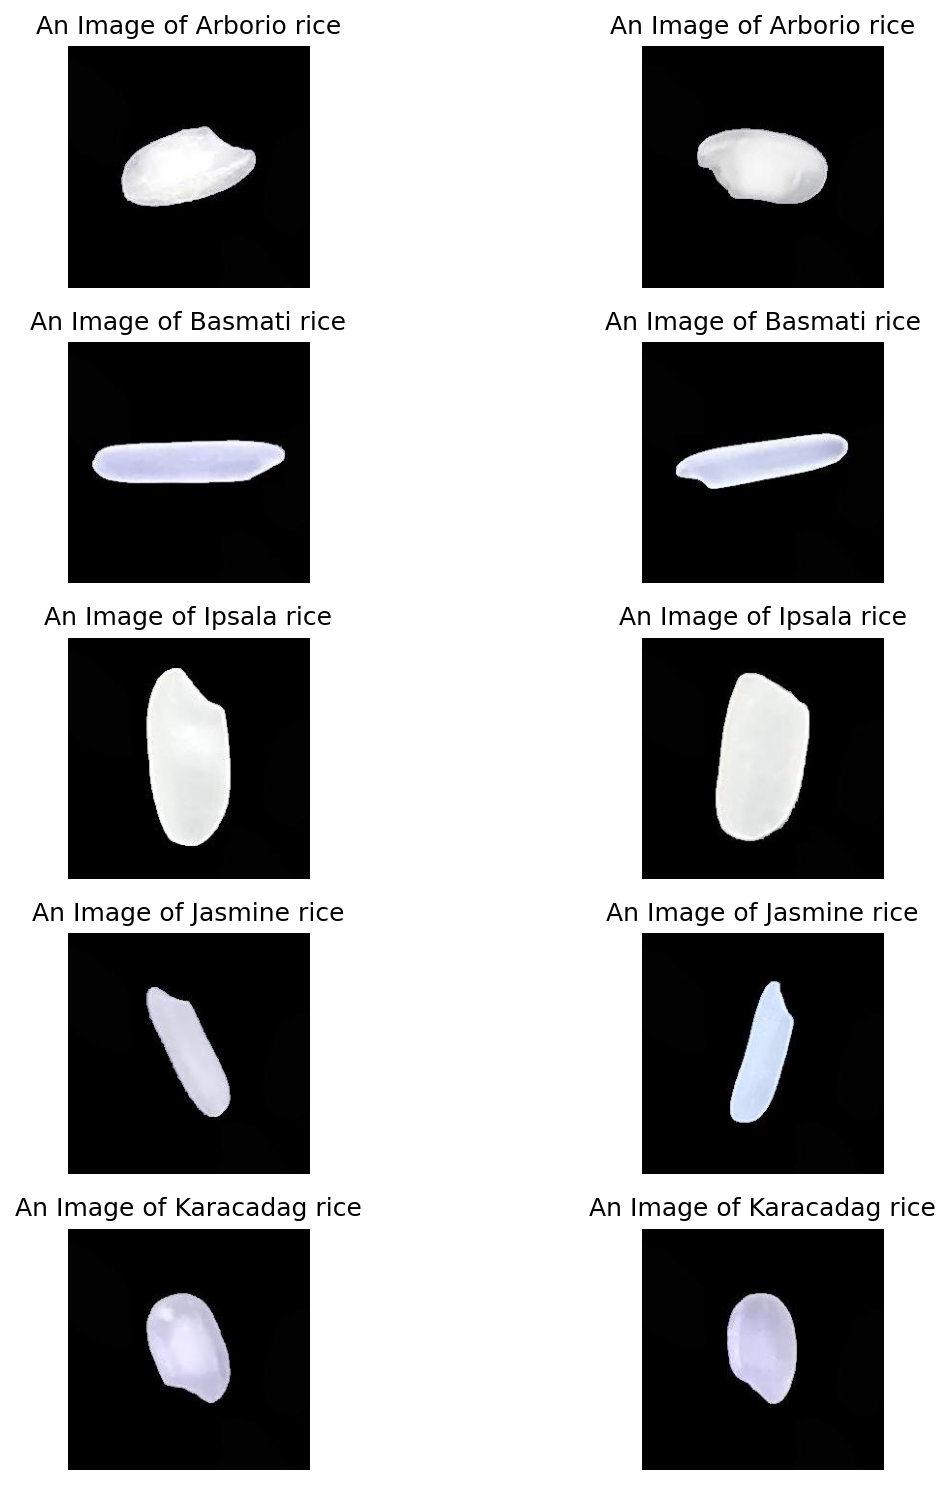

In [8]:
show(2,[image_arborio,image_basmati,image_ipsala,image_jasmine,image_karacadag],["Arborio","Basmati","Ipsala","Jasmine","Karacadag"])

In [9]:
print(f"Arborio\nTrain:{.75*len(image_arborio)}\nTest:{.20*len(image_arborio)}\nvalidation:{.05*len(image_arborio)}")

Arborio
Train:11250.0
Test:3000.0
validation:750.0


<div style="display:block; width:100%; box-sizing:border-box;font-size:17px;margin:12px 0; padding:16px 20px; border-radius:12px; line-height:1.9;
            background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">Here we are using index but the images are bing seperated randomly.</div>

In [10]:
train_arborio=image_arborio[:11250]
test_arborio=image_arborio[11250:14250]
val_arborio=image_arborio[14250:15000]
print("Arborio",len(train_arborio),len(test_arborio),len(val_arborio))

train_basmati=image_basmati[:11250]
test_basmati=image_basmati[11250:14250]
val_basmati=image_basmati[14250:15000]
print("Basmati:",len(train_basmati),len(test_basmati),len(val_basmati))

train_ipsala=image_ipsala[:11250]
test_ipsala=image_ipsala[11250:14250]
val_ipsala=image_ipsala[14250:15000]
print("Ipsala",len(train_ipsala),len(test_ipsala),len(val_ipsala))

train_jasmine=image_jasmine[:11250]
test_jasmine=image_jasmine[11250:14250]
val_jasmine=image_jasmine[14250:15000]
print("Jasmine",len(train_jasmine),len(test_jasmine),len(val_jasmine))

train_karacadag=image_karacadag[:11250]
test_karacadag=image_karacadag[11250:14250]
val_karacadag=image_karacadag[14250:15000]
print("Karacadag",len(train_karacadag),len(test_karacadag),len(val_karacadag))

Arborio 11250 3000 750
Basmati: 11250 3000 750
Ipsala 11250 3000 750
Jasmine 11250 3000 750
Karacadag 11250 3000 750


In [11]:
train_arborio_df=pd.DataFrame({"image":train_arborio,"label":"arborio"})
train_basmati_df=pd.DataFrame({"image":train_basmati,"label":"basmati"})
train_ipsala_df=pd.DataFrame({"image":train_ipsala,"label":"ipsala"})
train_jasmine_df=pd.DataFrame({"image":train_jasmine,"label":"jasmine"})
train_karacadag_df=pd.DataFrame({"image":train_karacadag,"label":"karacadag"})

In [12]:
test_arborio_df=pd.DataFrame({"image":test_arborio,"label":"arborio"})
test_basmati_df=pd.DataFrame({"image":test_basmati,"label":"basmati"})
test_ipsala_df=pd.DataFrame({"image":test_ipsala,"label":"ipsala"})
test_jasmine_df=pd.DataFrame({"image":test_jasmine,"label":"jasmine"})
test_karacadag_df=pd.DataFrame({"image":test_karacadag,"label":"karacadag"})

In [13]:
val_arborio_df=pd.DataFrame({"image":val_arborio,"label":"arborio"})
val_basmati_df=pd.DataFrame({"image":val_basmati,"label":"basmati"})
val_ipsala_df=pd.DataFrame({"image":val_ipsala,"label":"ipsala"})
val_jasmine_df=pd.DataFrame({"image":val_jasmine,"label":"jasmine"})
val_karacadag_df=pd.DataFrame({"image":val_karacadag,"label":"karacadag"})

In [14]:
train_df=pd.concat([train_arborio_df,train_basmati_df,train_ipsala_df,train_jasmine_df,train_karacadag_df])
test_df=pd.concat([test_arborio_df,test_basmati_df,test_ipsala_df,test_jasmine_df,test_karacadag_df])
val_df=pd.concat([val_arborio_df,val_basmati_df,val_ipsala_df,val_jasmine_df,val_karacadag_df])

<div style="display:block; width:100%; box-sizing:border-box;font-size:17px;margin:12px 0; padding:16px 20px; border-radius:12px; line-height:1.9;
            background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">I like to allways check every step to prevent the errors in future.The numbers are good here.
</div>

In [15]:
train_df.describe(include="all")

,image,label
count,56250,56250
unique,56250,5
top,/content/Rice_Image/Arborio/Arborio (13559).jpg,arborio
freq,1,11250


In [16]:
test_df.describe(include="all")

,image,label
count,15000,15000
unique,15000,5
top,/content/Rice_Image/Arborio/Arborio (4861).jpg,arborio
freq,1,3000


In [17]:
val_df.describe(include="all")

,image,label
count,3750,3750
unique,3750,5
top,/content/Rice_Image/Arborio/Arborio (12440).jpg,arborio
freq,1,750


In [18]:
random_img_hw=random.choice(train_arborio)

<div style="display:block; width:100%; box-sizing:border-box;font-size:17px;margin:12px 0; padding:16px 20px; border-radius:12px; line-height:1.9;            background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">Preparing data for the model.I allways go for simplest model first just to see what can be improved after training .As you can see i used a simple Generator ,didnt changed the picture size and kept the simple structure for my model.
</div>

In [19]:
img=imread(random_img_hw)
height,width=img.shape[:2]
print(height)
print(width)

250
250


In [20]:
batchsize=20

In [21]:
traingenerator=keras.preprocessing.image.ImageDataGenerator(rescale=1./255.)
testgenerator=keras.preprocessing.image.ImageDataGenerator(rescale=1./255.)
valgenerator=keras.preprocessing.image.ImageDataGenerator(rescale=1./255.)

In [22]:
train_data=traingenerator.flow_from_dataframe(
    dataframe=train_df,
    class_mode="categorical",
    x_col="image",
    y_col="label",
    batch_size=batchsize,
    seed=42,
    shuffle=True
)

test_data=testgenerator.flow_from_dataframe(
    dataframe=test_df,
    class_mode="categorical",
    x_col="image",
    y_col="label",
    batch_size=batchsize,
    seed=42,
    shuffle=False
)

val_data=valgenerator.flow_from_dataframe(
    dataframe=val_df,
    class_mode="categorical",
    x_col="image",
    y_col="label",
    batch_size=batchsize,
    seed=42,
    shuffle=False
)

Found 56250 validated image filenames belonging to 5 classes.
Found 15000 validated image filenames belonging to 5 classes.
Found 3750 validated image filenames belonging to 5 classes.


<div style="display:block; width:100%; box-sizing:border-box;background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:30px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  The CNN Model NO. #1 🧠
</div>

In [23]:
cnn=tf.keras.models.Sequential()

In [24]:
cnn.add(tf.keras.layers.Input(shape=(256,256,3)))
cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation="relu"))

In [25]:
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

In [26]:
cnn.add(tf.keras.layers.Flatten())

In [27]:
cnn.add(tf.keras.layers.Dense(units=128,activation="relu"))

In [28]:
cnn.add(tf.keras.layers.Dense(units=5,activation="softmax"))

In [29]:
cnn.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [30]:
tf.debugging.set_log_device_placement(True)
m1=cnn.fit(x=train_data,validation_data=val_data,epochs=10)

Epoch 1/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 174s 60ms/step - accuracy: 0.9602 - loss: 0.1357 - val_accuracy: 0.9691 - val_loss: 0.0943
Epoch 2/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 171s 61ms/step - accuracy: 0.9846 - loss: 0.0440 - val_accuracy: 0.9845 - val_loss: 0.0484
Epoch 3/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 169s 60ms/step - accuracy: 0.9898 - loss: 0.0295 - val_accuracy: 0.9704 - val_loss: 0.0904
Epoch 4/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 152s 54ms/step - accuracy: 0.9913 - loss: 0.0254 - val_accuracy: 0.9845 - val_loss: 0.0590
Epoch 5/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 161s 57ms/step - accuracy: 0.9956 - loss: 0.0124 - val_accuracy: 0.9640 - val_loss: 0.1786
Epoch 6/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 164s 58ms/step - accuracy: 0.9964 - loss: 0.0104 - val_accuracy: 0.9709 - val_loss: 0.1551
Epoch 7/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 162s 57ms/step - accuracy: 0.9986 - loss: 0.0045 - val_accuracy: 0.9765 - val_loss: 0.1757
Epoch 8/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 144s 51ms/step - accuracy: 

In [31]:
result=cnn.predict(test_data)

750/750 ━━━━━━━━━━━━━━━━━━━━ 38s 50ms/step


<div style="display:block; width:100%; box-sizing:border-box;font-size:17px;margin:12px 0; padding:16px 20px; border-radius:12px; line-height:1.9;background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">The result for this simple model was decent .as you can see we have overfiting proble there is a gap between accuracy and value accuracy.
</div>

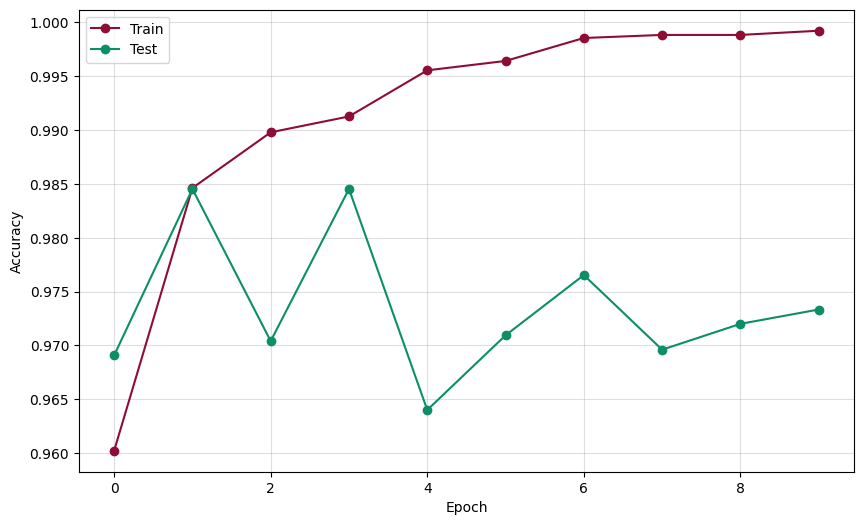

In [32]:
plt.figure(figsize=(10,6))
plt.plot(m1.history['accuracy'],marker="o",color="#8F0C35")
plt.plot(m1.history['val_accuracy'],marker="o",color="#0C8F66")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["Train","Test"])
plt.grid(alpha=0.4)
plt.show()

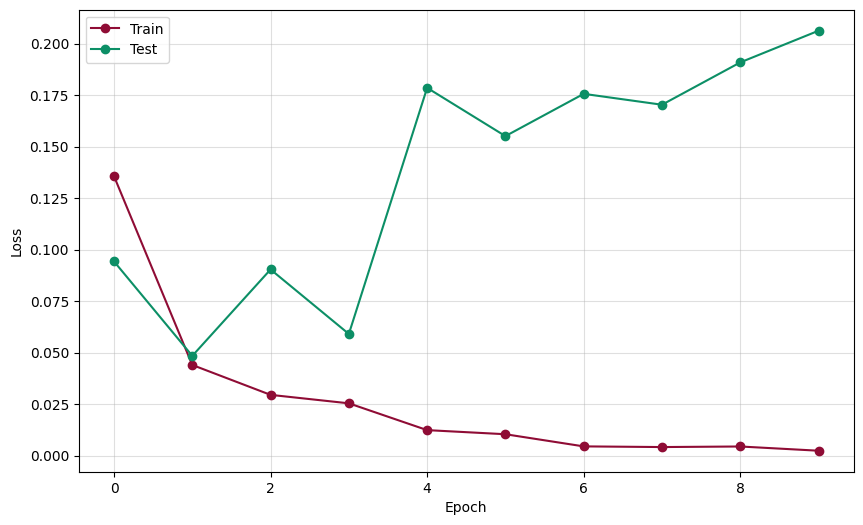

In [33]:
plt.figure(figsize=(10,6))
plt.plot(m1.history['loss'],marker="o",color="#8F0C35")
plt.plot(m1.history['val_loss'],marker="o",color="#0C8F66")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["Train","Test"])
plt.grid(alpha=0.4)
plt.show()

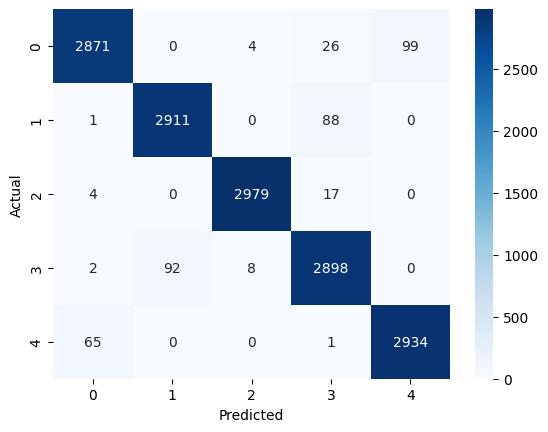

In [34]:
y_pred=np.argmax(result,axis=1)
y_test=test_data.classes
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

<div style="display:block; width:100%; box-sizing:border-box;font-size:17px;margin:12px 0; padding:16px 20px; border-radius:12px; line-height:1.9;background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">Since this data images are all rices with black background wich dosent help the model and dont have any valuable information in it at all we can reduce the target size so the model can focuse on the rice geometry this was the process  time will be reduced .
</div>

In [35]:
train_data2=traingenerator.flow_from_dataframe(
    dataframe=train_df,
    class_mode="categorical",
    x_col="image",
    y_col="label",
    batch_size=batchsize,
    seed=42,
    shuffle=True,
    target_size=(128,128)
)

test_data2=testgenerator.flow_from_dataframe(
    dataframe=test_df,
    class_mode="categorical",
    x_col="image",
    y_col="label",
    batch_size=batchsize,
    seed=42,
    shuffle=False,
    target_size=(128,128)
)

val_data2=valgenerator.flow_from_dataframe(
    dataframe=val_df,
    class_mode="categorical",
    x_col="image",
    y_col="label",
    batch_size=batchsize,
    seed=42,
    shuffle=False,
    target_size=(128,128)
)

Found 56250 validated image filenames belonging to 5 classes.
Found 15000 validated image filenames belonging to 5 classes.
Found 3750 validated image filenames belonging to 5 classes.


<div style="display:block; width:100%; box-sizing:border-box;background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:30px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  The CNN Model NO. #2 🧠
</div>

In [36]:
cnn2=tf.keras.models.Sequential()

In [37]:
cnn2.add(tf.keras.layers.Input(shape=(128,128,3)))

In [38]:
cnn2.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation="relu"))

In [39]:
cnn2.add(tf.keras.layers.MaxPool2D(pool_size=3,strides=2))

In [40]:
cnn2.add(tf.keras.layers.Flatten())

In [41]:
cnn2.add(tf.keras.layers.Dense(units=128,activation="relu"))

In [42]:
cnn2.add(tf.keras.layers.Dense(units=5,activation="softmax"))

In [43]:
cnn2.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [44]:
tf.debugging.set_log_device_placement(True)
m2=cnn2.fit(x=train_data2,validation_data=val_data2,epochs=10)

Epoch 1/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 77s 26ms/step - accuracy: 0.9700 - loss: 0.0942 - val_accuracy: 0.9853 - val_loss: 0.0442
Epoch 2/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 70s 25ms/step - accuracy: 0.9864 - loss: 0.0392 - val_accuracy: 0.9736 - val_loss: 0.0809
Epoch 3/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 67s 24ms/step - accuracy: 0.9891 - loss: 0.0327 - val_accuracy: 0.9635 - val_loss: 0.1102
Epoch 4/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 67s 24ms/step - accuracy: 0.9835 - loss: 0.0474 - val_accuracy: 0.9763 - val_loss: 0.0716
Epoch 5/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 68s 24ms/step - accuracy: 0.9880 - loss: 0.0345 - val_accuracy: 0.9784 - val_loss: 0.0792
Epoch 6/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 69s 25ms/step - accuracy: 0.9923 - loss: 0.0223 - val_accuracy: 0.9867 - val_loss: 0.0577
Epoch 7/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 65s 23ms/step - accuracy: 0.9952 - loss: 0.0140 - val_accuracy: 0.9853 - val_loss: 0.0625
Epoch 8/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 67s 24ms/step - accuracy: 0.9958 -

In [45]:
result2=cnn2.predict(test_data2)

750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step


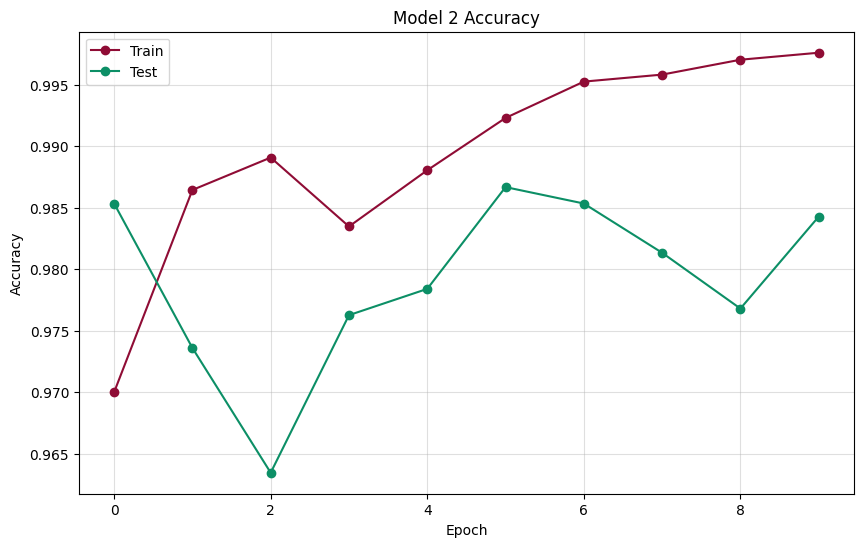

In [61]:
plt.figure(figsize=(10,6))
plt.plot(m2.history['accuracy'],marker="o",color="#8F0C35")
plt.plot(m2.history['val_accuracy'],marker="o",color="#0C8F66")
plt.title("Model 2 Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["Train","Test"])
plt.grid(alpha=0.4)
plt.show()

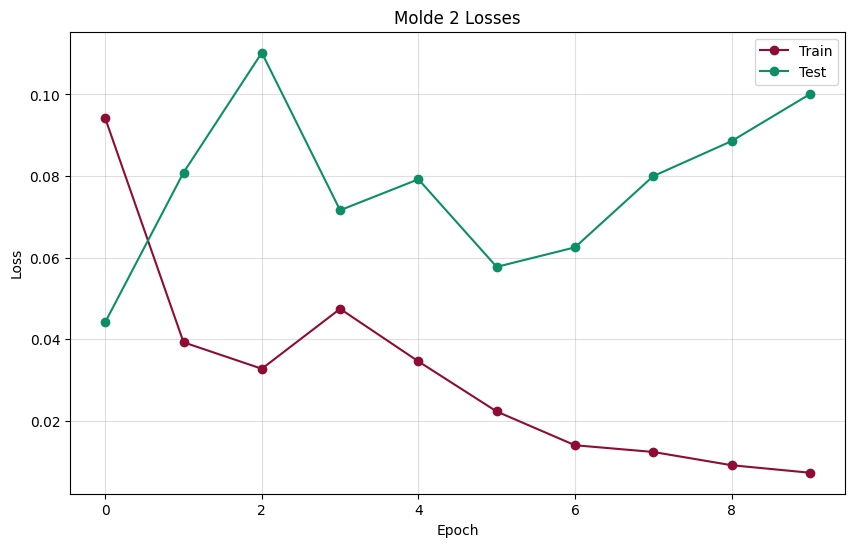

In [60]:
plt.figure(figsize=(10,6))
plt.plot(m2.history['loss'],marker="o",color="#8F0C35")
plt.plot(m2.history['val_loss'],marker="o",color="#0C8F66")
plt.title("Molde 2 Losses")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["Train","Test"])
plt.grid(alpha=0.4)
plt.show()

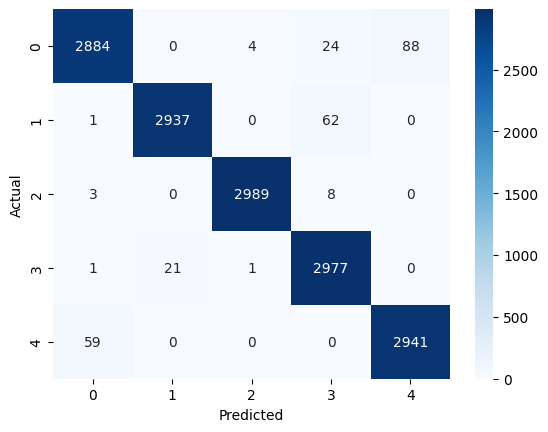

In [48]:
y_pred2=np.argmax(result2,axis=1)
y_test2=test_data2.classes
cm2=confusion_matrix(y_test2, y_pred2)
sns.heatmap(cm2, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

<div style="display:block; width:100%; box-sizing:border-box;font-size:17px;margin:12px 0; padding:16px 20px; border-radius:12px; line-height:1.9;background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">The results above show that size reduction defentliey helped .Overfiting gape and training time are bothe reduced and the plots and confusion matrixe are showing better numbers.Now for next model i decided to use rotation ,horizantal and vertical flips for train image genrator so the model can be trained by images that includes rice in all possible shapes .
</div>

In [49]:
traingenerator2=keras.preprocessing.image.ImageDataGenerator(rescale=1./255.,rotation_range=30,
                                                             horizontal_flip=True,vertical_flip=True,
                                                             fill_mode="constant",cval=0)

In [50]:
train_data3=traingenerator2.flow_from_dataframe(
    dataframe=train_df,
    class_mode="categorical",
    x_col="image",
    y_col="label",
    batch_size=batchsize,
    seed=42,
    shuffle=True,
    target_size=(96,96)
)

test_data3=testgenerator.flow_from_dataframe(
    dataframe=test_df,
    class_mode="categorical",
    x_col="image",
    y_col="label",
    batch_size=batchsize,
    seed=42,
    shuffle=False,
    target_size=(96,96)
)

val_data3=valgenerator.flow_from_dataframe(
    dataframe=val_df,
    class_mode="categorical",
    x_col="image",
    y_col="label",
    batch_size=batchsize,
    seed=42,
    shuffle=False,
    target_size=(96,96)
)

Found 56250 validated image filenames belonging to 5 classes.
Found 15000 validated image filenames belonging to 5 classes.
Found 3750 validated image filenames belonging to 5 classes.


<div style="display:block; width:100%; box-sizing:border-box;background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:30px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  The CNN Model NO. #3 🧠
</div>

In [51]:
cnn3=tf.keras.models.Sequential()

In [52]:
cnn3.add(tf.keras.layers.Input(shape=(96,96,3)))

In [53]:
cnn3.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation="relu"))

In [54]:
cnn3.add(tf.keras.layers.MaxPool2D(pool_size=3,strides=2))

In [55]:
cnn3.add(tf.keras.layers.Flatten())

In [56]:
cnn3.add(tf.keras.layers.Dense(units=128,activation="relu"))

In [57]:
cnn3.add(tf.keras.layers.Dense(units=5,activation="softmax"))

In [58]:
cnn3.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

<div style="display:block; width:100%; box-sizing:border-box;font-size:17px;margin:12px 0; padding:16px 20px; border-radius:12px; line-height:1.9;background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">ckpt is gonna check the specified scores each epoch and if they have improved that epoch will be saved and can be used later.
</div>

In [69]:
ckpt_loss=keras.callbacks.ModelCheckpoint(
    "cnn3_best_loss.keras",
    monitor="val_loss", mode="min",
    save_best_only=True, verbose=1
)
ckpt_acc = keras.callbacks.ModelCheckpoint(
    "cnn3_best_acc.keras",
    monitor="val_accuracy", mode="max",
    save_best_only=True, verbose=1
)
m3=cnn3.fit(x=train_data3,validation_data=val_data3,epochs=10,callbacks=[ckpt_loss, ckpt_acc])

Epoch 1/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9941 - loss: 0.0185
Epoch 1: val_loss improved from None to 0.03156, saving model to cnn3_best_loss.keras

Epoch 1: finished saving model to cnn3_best_loss.keras

Epoch 1: val_accuracy improved from None to 0.98907, saving model to cnn3_best_acc.keras

Epoch 1: finished saving model to cnn3_best_acc.keras
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 195s 69ms/step - accuracy: 0.9934 - loss: 0.0216 - val_accuracy: 0.9891 - val_loss: 0.0316
Epoch 2/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.9943 - loss: 0.0184
Epoch 2: val_loss did not improve from 0.03156

Epoch 2: val_accuracy did not improve from 0.98907
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 200s 71ms/step - accuracy: 0.9933 - loss: 0.0208 - val_accuracy: 0.9789 - val_loss: 0.0666
Epoch 3/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9920 - loss: 0.0251
Epoch 3: val_loss did not improve from 0.03156

Epoch 3: val_accuracy did not improve from 0.98907
2813

In [70]:
files.download("cnn3_best_loss.keras")
files.download("cnn3_best_acc.keras")
result3=cnn3.predict(test_data3)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step


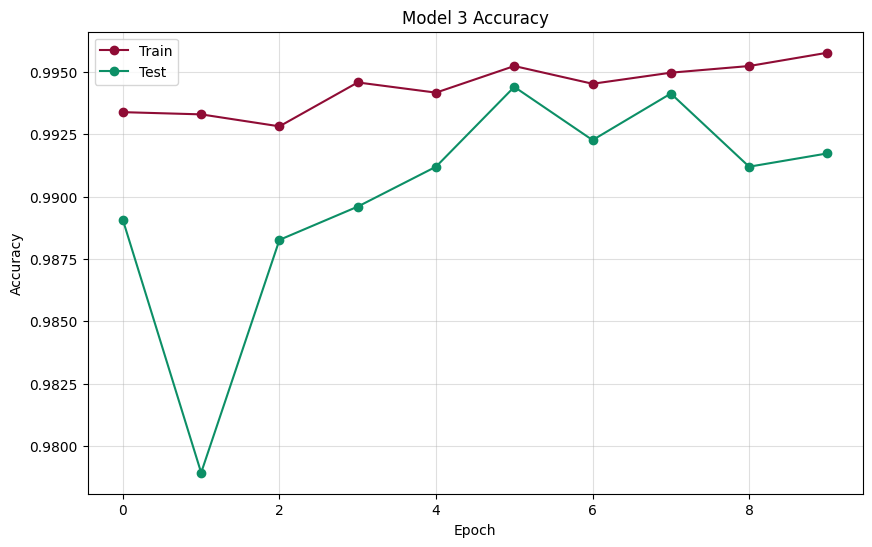

In [71]:
plt.figure(figsize=(10,6))
plt.plot(m3.history['accuracy'],marker="o",color="#8F0C35")
plt.plot(m3.history['val_accuracy'],marker="o",color="#0C8F66")
plt.title("Model 3 Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["Train","Test"])
plt.grid(alpha=0.4)
plt.show()

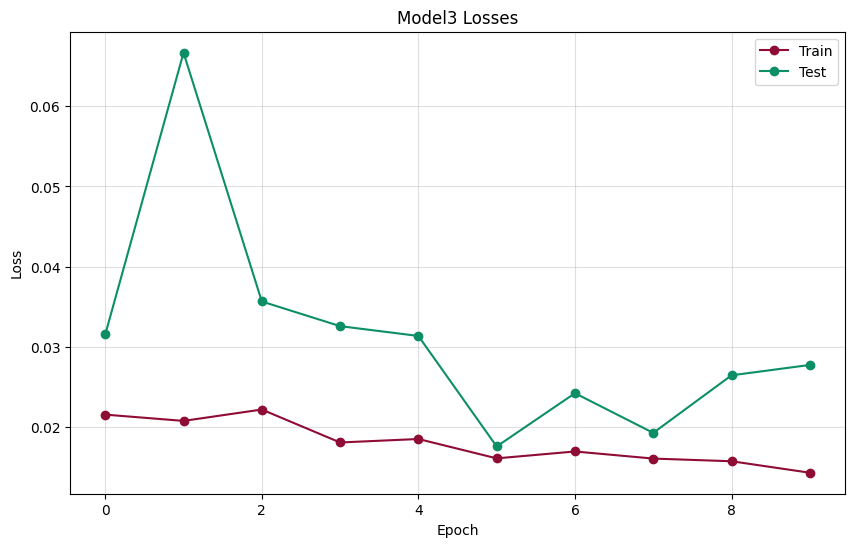

In [72]:
plt.figure(figsize=(10,6))
plt.plot(m3.history['loss'],marker="o",color="#8F0C35")
plt.plot(m3.history['val_loss'],marker="o",color="#0C8F66")
plt.title("Model3 Losses")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["Train","Test"])
plt.grid(alpha=0.4)
plt.show()

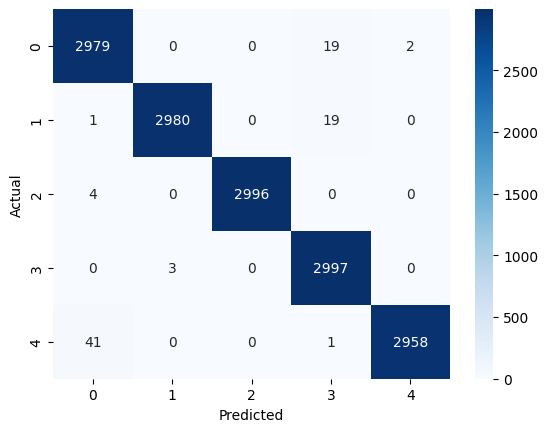

In [73]:
y_pred3=np.argmax(result3,axis=1)
y_test3=test_data3.classes
cm3=confusion_matrix(y_test3, y_pred3)
sns.heatmap(cm3, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

<div style="display:block; width:100%; box-sizing:border-box;font-size:17px;margin:12px 0; padding:16px 20px; border-radius:12px; line-height:1.9;background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">The size reduction helped the accuracie and improved the detection.
</div>

In [74]:
train_data4=traingenerator2.flow_from_dataframe(
    dataframe=train_df,
    class_mode="categorical",
    x_col="image",
    y_col="label",
    batch_size=batchsize,
    seed=42,
    shuffle=True,
    target_size=(128,128)
)

test_data4=testgenerator.flow_from_dataframe(
    dataframe=test_df,
    class_mode="categorical",
    x_col="image",
    y_col="label",
    batch_size=batchsize,
    seed=42,
    shuffle=False,
    target_size=(128,128)
)

val_data4=valgenerator.flow_from_dataframe(
    dataframe=val_df,
    class_mode="categorical",
    x_col="image",
    y_col="label",
    batch_size=batchsize,
    seed=42,
    shuffle=False,
    target_size=(128,128)
)

Found 56250 validated image filenames belonging to 5 classes.
Found 15000 validated image filenames belonging to 5 classes.
Found 3750 validated image filenames belonging to 5 classes.


<div style="display:block; width:100%; box-sizing:border-box;background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:30px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  The CNN Model NO. #4 🧠
</div>

<div style="display:block; width:100%; box-sizing:border-box;font-size:17px;margin:12px 0; padding:16px 20px; border-radius:12px; line-height:1.9;
            background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">For this model i decided to add more layers and used 128x128 size just in case so we dont losse the graine edges .
</div>

In [75]:
cnn4=tf.keras.Sequential()

In [76]:
cnn4.add(tf.keras.layers.Input(shape=(128,128,3)))

In [77]:
cnn4.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation="relu"))

In [78]:
cnn4.add(tf.keras.layers.MaxPool2D(pool_size=3,strides=2))

In [79]:
cnn4.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,activation="relu"))

In [80]:
cnn4.add(tf.keras.layers.MaxPool2D(pool_size=3,strides=2))

In [81]:
cnn4.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,activation="relu"))

In [82]:
cnn4.add(tf.keras.layers.MaxPool2D(pool_size=3,strides=2))

In [83]:
cnn4.add(tf.keras.layers.Flatten())

In [84]:
cnn4.add(tf.keras.layers.Dense(units=64,activation="relu"))

In [85]:
cnn4.add(tf.keras.layers.Dense(units=5,activation="softmax"))

In [86]:
cnn4.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [88]:
ckpt_loss2=keras.callbacks.ModelCheckpoint(
    "cnn4_best_loss.keras",
    monitor="val_loss", mode="min",
    save_best_only=True, verbose=1
)
ckpt_acc2= keras.callbacks.ModelCheckpoint(
    "cnn4_best_acc.keras",
    monitor="val_accuracy", mode="max",
    save_best_only=True, verbose=1
)
m4=cnn4.fit(x=train_data4,validation_data=val_data4,epochs=10,callbacks=[ckpt_loss2, ckpt_acc2])

Epoch 1/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.9252 - loss: 0.2055
Epoch 1: val_loss improved from None to 0.11719, saving model to cnn4_best_loss.keras

Epoch 1: finished saving model to cnn4_best_loss.keras

Epoch 1: val_accuracy improved from None to 0.96240, saving model to cnn4_best_acc.keras

Epoch 1: finished saving model to cnn4_best_acc.keras
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 311s 108ms/step - accuracy: 0.9564 - loss: 0.1254 - val_accuracy: 0.9624 - val_loss: 0.1172
Epoch 2/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.9830 - loss: 0.0520
Epoch 2: val_loss improved from 0.11719 to 0.03363, saving model to cnn4_best_loss.keras

Epoch 2: finished saving model to cnn4_best_loss.keras

Epoch 2: val_accuracy improved from 0.96240 to 0.98773, saving model to cnn4_best_acc.keras

Epoch 2: finished saving model to cnn4_best_acc.keras
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 304s 108ms/step - accuracy: 0.9853 - loss: 0.0438 - val_accuracy: 0.9877 - val_loss: 0

In [89]:
files.download("cnn4_best_loss.keras")
files.download("cnn4_best_acc.keras")
result4=cnn4.predict(test_data4)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step


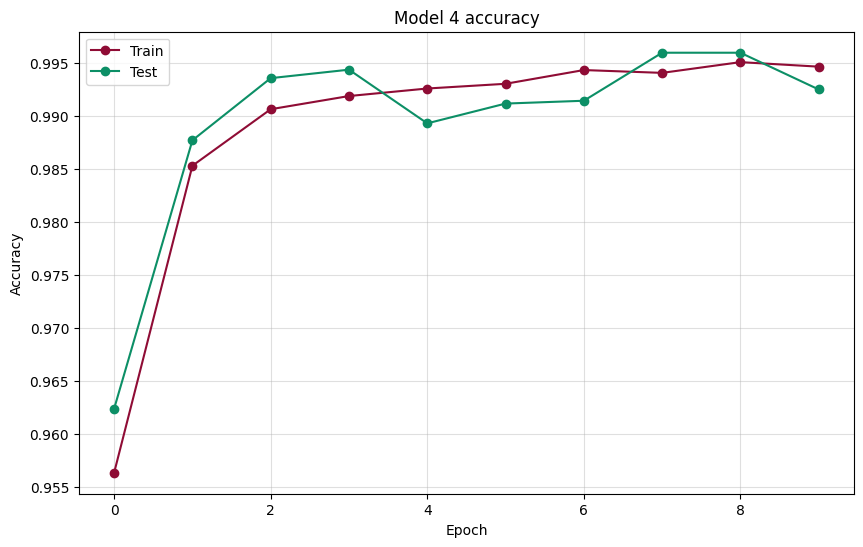

In [90]:
plt.figure(figsize=(10,6))
plt.plot(m4.history['accuracy'],marker="o",color="#8F0C35")
plt.plot(m4.history['val_accuracy'],marker="o",color="#0C8F66")
plt.title("Model 4 accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["Train","Test"])
plt.grid(alpha=0.4)
plt.show()

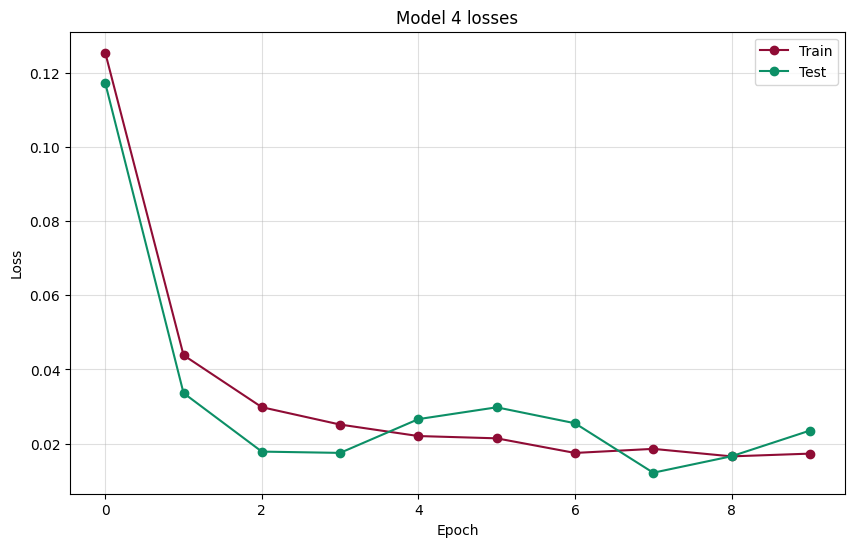

In [91]:
plt.figure(figsize=(10,6))
plt.plot(m4.history['loss'],marker="o",color="#8F0C35")
plt.plot(m4.history['val_loss'],marker="o",color="#0C8F66")
plt.title("Model 4 losses")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["Train","Test"])
plt.grid(alpha=0.4)
plt.show()

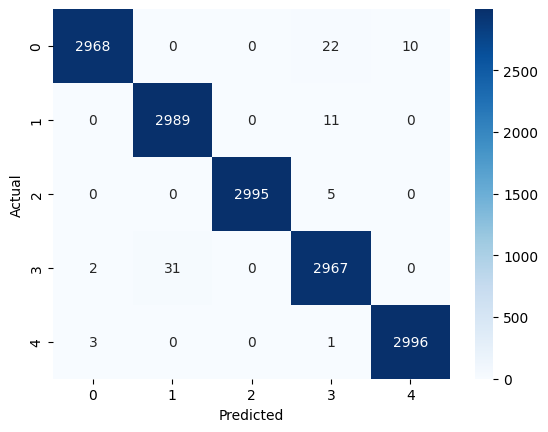

In [92]:
y_pred4=np.argmax(result4,axis=1)
y_test4=test_data4.classes
cm4=confusion_matrix(y_test4, y_pred4)
sns.heatmap(cm4, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

<div style="display:block; width:100%; box-sizing:border-box;font-size:17px;margin:12px 0; padding:16px 20px; border-radius:12px; line-height:1.9;
            background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">The layers certainley improved the performace Even though the run time is higher but the FP adn Fn is reduced to 83 wich is a greate outcome.
</div>

<div align="center">
  <a href="https://github.com/amir-hlj">
    <img src="https://cdn.jsdelivr.net/npm/simple-icons@v11/icons/github.svg"
         width="60">
  </a>
  <br>
  <strong>Visit My GitHub Profile</strong>
</div>